In [29]:
# 실습 단계 1

import torch
from ultralytics import YOLO
print('torch:', torch.__version__)
print('mps:', torch.backends.mps.is_available())

model = YOLO('yolov8s-seg.pt')
print('model loaded')

torch: 2.15.0
mps: True
model loaded


In [30]:
# 실습 단계 2

import glob
imgs = sorted(
    glob.glob('../data/images/**/*.jpg', recursive=True)
)

print("영상 수:", len(imgs))
print("예시:", imgs[0] if imgs else "없음")

영상 수: 3970
예시: ../data/images/test/UCT011_2021_01_06_001_6840_jpg.rf.b637f27b7bdf92480508621d4431576c.jpg


밝기 평균: 144.5
밝기 표준편차: 17.1


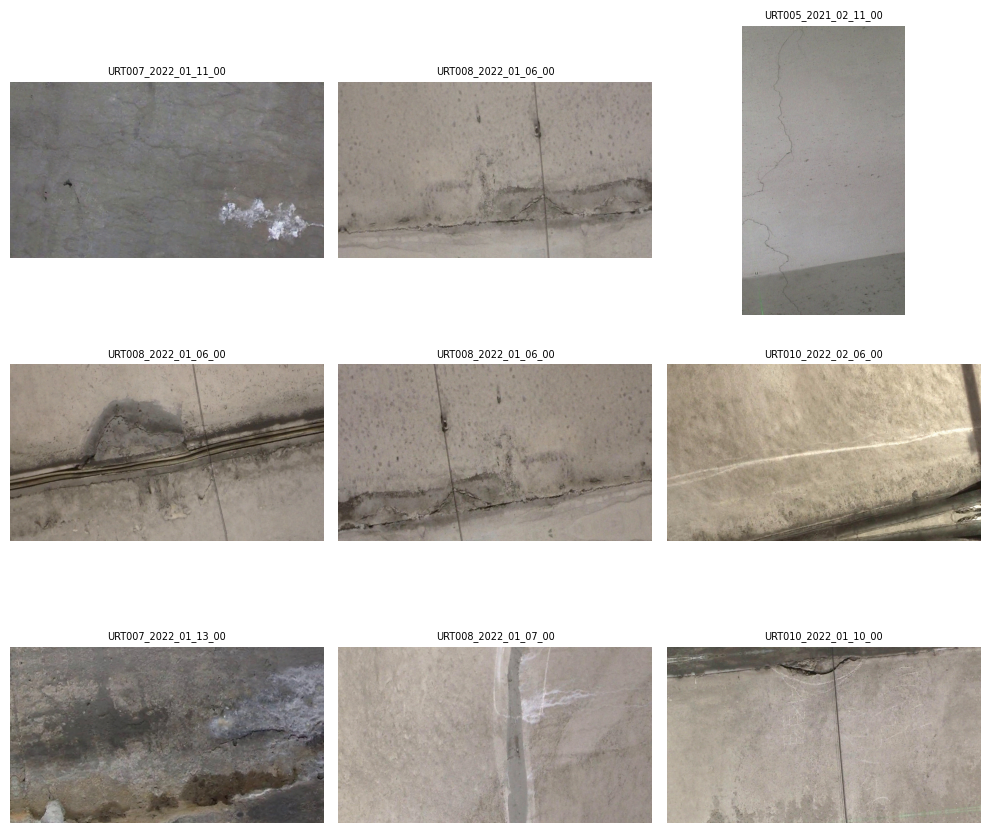

In [37]:
# 실습 단계 3

import cv2
import random
import matplotlib.pyplot as plt
from pathlib import Path

n = min(9, len(imgs))
sample = random.sample(imgs, n)

fig, ax = plt.subplots(3,3, figsize=(10,9))
axes = ax.ravel()

for a in axes:
    a.axis("off")

for a, p in zip(axes, sample):
    im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    a.imshow(im)
    a.set_title(Path(p).name[:20], fontsize=7)

out = Path("report/week_1/component")
out.mkdir(parents=True, exist_ok=True)
plt.tight_layout()
plt.savefig("./report/week_1/component/samples9.png", dpi=110)

if imgs:
    gray = cv2.imread(imgs[0], 0)
    print("밝기 평균:", round(gray.mean(), 1))
    print("밝기 표준편차:", round(gray.std(), 1))